# Analyze a Parameter Ensemble

In the previous notebook we ran 6 ensemble members, each setting one of 3 FATES parameters to its minimum or maximum value. Together with the default run (`BONA.FATESsp`), that gives the 2N + 1 = 7 runs of a one-at-a-time (OAT) experiment.

In this notebook we will:

1. Load the output of every member, and of the default run
2. Compare each member to the default over time
3. Summarize how sensitive each output is to each parameter

OAT tells us the **direction** and **size** of each parameter's effect around the default. It can't tell us how parameters **interact**, or how the model responds **between** the minimum and maximum (see the [overview](sensitivity_overview.ipynb)).

We will look at four outputs:

| Variable | Description | Units |
|---|---|---|
| `FATES_GPP` | Gross primary production | kg C m<sup>-2</sup> s<sup>-1</sup> (we'll convert to g C m<sup>-2</sup> d<sup>-1</sup>) |
| `FCTR` | Canopy transpiration | W m<sup>-2</sup> |
| `FSH` | Sensible heat flux | W m<sup>-2</sup> |
| `FSA` | Absorbed solar radiation | W m<sup>-2</sup> |


<div class="alert alert-warning">
<strong>Note:</strong> Unlike previous notebooks in this section, we will no longer be using the <code>meristem</code> environment as our kernel. Check (or change) your kernel (see upper right corner, above). It should be either <code>NPL 2025a</code> or <code>NPL 2025b</code>.
</div>

In [195]:
from pathlib import Path
import functools
import os

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import xarray as xr

user = os.getenv('USER')
print(f"username is {user}, update to your username if this is not correct")

username is afoster, update to your username if this is not correct


In [3]:
VARIABLES = ["FATES_GPP", "FCTR", "FSH", "FSA"]
YEARS = slice("2014-01-01", "2015-12-31")

## Step 1: Load the manifest

The manifest we wrote at the end of the last notebook has one row per member. For each member it records which parameter was changed and in which direction (from the paramgen key), whether the run finished, and where its output was archived.


In [4]:
manifest = pd.read_csv(f"/glade/u/home/{user}/oat_manifest.csv")
manifest[["member", "parameter", "direction", "run_status", "run_archive_dir"]]

,member,parameter,direction,run_status,run_archive_dir
0,fates_oat_0000,fates_leaf_stomatal_intercept,minimum,done,/glade/derecho/scratch/afoster/oat_ensemble/ar...
1,fates_oat_0001,fates_leaf_stomatal_intercept,maximum,done,/glade/derecho/scratch/afoster/oat_ensemble/ar...
2,fates_oat_0002,fates_leaf_vcmax25top,minimum,done,/glade/derecho/scratch/afoster/oat_ensemble/ar...
3,fates_oat_0003,fates_leaf_vcmax25top,maximum,done,/glade/derecho/scratch/afoster/oat_ensemble/ar...
4,fates_oat_0004,fates_rad_leaf_clumping_index,minimum,done,/glade/derecho/scratch/afoster/oat_ensemble/ar...
5,fates_oat_0005,fates_rad_leaf_clumping_index,maximum,done,/glade/derecho/scratch/afoster/oat_ensemble/ar...


In [5]:
not_done = manifest[manifest["run_status"] != "done"]
if not_done.empty:
    print("All members are done.")
else:
    print("These members haven't finished; see Step 7 of the previous notebook:")
    print(not_done[["member", "run_status"]])

All members are done.


If any members are not done, either wait for them to finish, or if they failed, fix any problems and `retry` (see [previous notebook](submit_ensemble.ipynb)).

## Step 2: Load the model output

The functions below open every monthly h0 file for one run, keeps our variables and years, and converts GPP to more readable units.

In [91]:
def preprocess(data_set, variables) -> xr.Dataset:
    """Preprocesses an xarray Dataset by subsetting to specific variables and years"""
    return data_set[variables]

def load_run(archive_dir, variables=VARIABLES, years=YEARS):
    """Load one run's monthly averaged (h0a) history output as an xarray Dataset."""
    files = sorted(Path(archive_dir, "lnd", "hist").glob("*.clm2.h0a*.nc"))
    ds = xr.open_mfdataset(
        files,
        preprocess=functools.partial(preprocess, variables=variables),
        combine="by_coords",
        decode_timedelta=True,
        )

    ds = ds.sel(time=years)

    # kg C m-2 s-1 -> g C m-2 d-1
    ds["FATES_GPP"] = ds["FATES_GPP"] * 1000 * 86400
    ds["FATES_GPP"].attrs["units"] = "g C m-2 d-1"
    ds["FATES_GPP"].attrs["long_name"] = "gross primary production"
    
    return ds.load().isel(lndgrid=0)

Load every member, and stack them along a new `member` dimension. We also attach each member's `parameter` and `direction`, so we can select members by them later.

In [92]:
ensemble = xr.concat(
    [load_run(d) for d in manifest["run_archive_dir"]],
    dim=pd.Index(manifest["member"], name="member"),
)
ensemble = ensemble.assign_coords(
    parameter=("member", manifest["parameter"].values),
    direction=("member", manifest["direction"].values),
)
ensemble

<xarray.Dataset> Size: 3kB
Dimensions:    (member: 6, time: 24)
Coordinates:
  * time       (time) object 192B 2014-01-16 12:00:00 ... 2015-12-16 12:00:00
  * member     (member) object 48B 'fates_oat_0000' ... 'fates_oat_0005'
    parameter  (member) object 48B 'fates_leaf_stomatal_intercept' ... 'fates...
    direction  (member) object 48B 'minimum' 'maximum' ... 'minimum' 'maximum'
Data variables:
    FATES_GPP  (member, time) float64 1kB 0.0 0.0 0.0 ... 0.004886 0.000101
    FCTR       (member, time) float32 576B 0.0 0.0 0.0 ... 0.01903 0.00264
    FSH        (member, time) float32 576B -8.002 -3.016 -5.264 ... 16.76 6.647
    FSA        (member, time) float32 576B 0.7134 7.117 26.73 ... 2.85 0.3117
Attributes: (12/36)
    title:                                CLM History file information
    comment:                              NOTE: None of the variables are wei...
    Conventions:                          CF-1.0
    history:                              created on 11/04/26 09:45:25
    source:                               Community Terrestrial Systems Model
    hostname:                             derecho
    ...                                   ...
    ctype_urban_roof:                     71
    ctype_urban_sunwall:                  72
    ctype_urban_shadewall:                73
    ctype_urban_impervious_road:          74
    ctype_urban_pervious_road:            75
    time_period_freq:                     month_1

Now load the default run:

In [93]:
default_archive = f"/glade/derecho/scratch/{user}/archive/BONA.FATESsp"
default = load_run(default_archive)
default

<xarray.Dataset> Size: 672B
Dimensions:    (time: 24)
Coordinates:
  * time       (time) object 192B 2014-01-16 12:00:00 ... 2015-12-16 12:00:00
Data variables:
    FATES_GPP  (time) float64 192B 0.0 0.0 0.0 ... 0.1725 0.004929 0.0001021
    FCTR       (time) float32 96B 0.0 0.0 0.0 0.7672 ... 0.2273 0.01917 0.002662
    FSH        (time) float32 96B -8.002 -3.016 -5.264 ... 7.266 16.72 6.623
    FSA        (time) float32 96B 0.7134 7.117 26.73 ... 19.66 2.865 0.3037
Attributes: (12/36)
    title:                                CLM History file information
    comment:                              NOTE: None of the variables are wei...
    Conventions:                          CF-1.0
    history:                              created on 10/29/26 15:19:43
    source:                               Community Terrestrial Systems Model
    hostname:                             derecho
    ...                                   ...
    ctype_urban_roof:                     71
    ctype_urban_sunwall:                  72
    ctype_urban_shadewall:                73
    ctype_urban_impervious_road:          74
    ctype_urban_pervious_road:            75
    time_period_freq:                     month_1

## Step 3: Compare each member to the default

Each member changes only one parameter, so any difference from the default run is caused by that parameter. Plot, for each parameter, the default run along with its minimum and maximum members.

This helper function gives a member name given its parameter and direction:

### Grab the correct data arrays

In [156]:
def get_member(manifest, parameter, direction):
    """Name of the member that set `parameter` to its `direction` ('minimum' or 'maximum')."""
    rows = manifest[(manifest["parameter"] == parameter) & (manifest["direction"] == direction)]
    return rows["member"].item()

First we will pick a parameter and variable and pull out the minimum, maximum, and default data arrays for that variable:

In [157]:
var = "FATES_GPP"
param = "fates_leaf_vcmax25top"

lo = ensemble[var].sel(member=get_member(manifest, param, "minimum"))
hi = ensemble[var].sel(member=get_member(manifest, param, "maximum"))
base = default[var]

lo

<xarray.DataArray 'FATES_GPP' (time: 24)> Size: 192B
array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 1.46024603e-01,
       1.28022261e+00, 4.05945514e+00, 4.16881100e+00, 1.69928843e+00,
       4.65496314e-01, 7.34432653e-02, 0.00000000e+00, 0.00000000e+00,
       6.61530271e-05, 1.65991438e-04, 1.67648594e-02, 1.28097598e-01,
       1.36446655e+00, 4.27923744e+00, 4.13162332e+00, 1.76634481e+00,
       5.56234489e-01, 7.64342296e-02, 1.85126722e-03, 3.54904945e-05])
Coordinates:
  * time       (time) object 192B 2014-01-16 12:00:00 ... 2015-12-16 12:00:00
    member     <U14 56B 'fates_oat_0002'
    parameter  object 8B 'fates_leaf_vcmax25top'
    direction  object 8B 'minimum'
Attributes:
    units:      g C m-2 d-1
    long_name:  gross primary production

### Plot the time series

Next we will plot them next to each other:

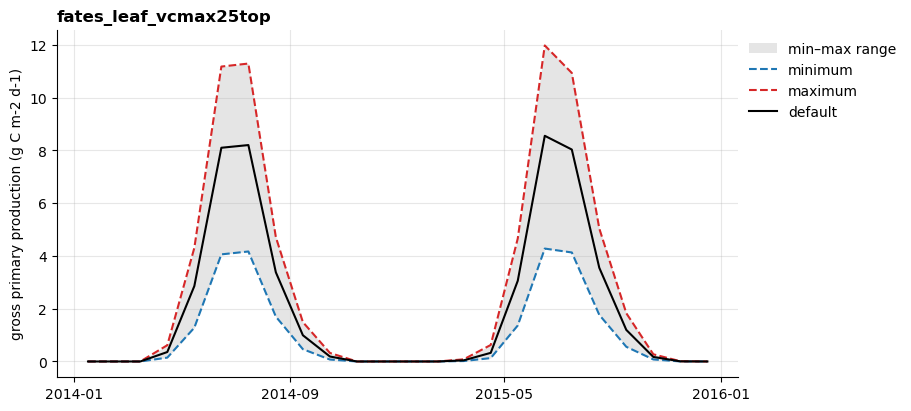

In [95]:
fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)

# shaded envelope between min and max
ax.fill_between(base["time"].values, lo, hi, color="tab:gray", alpha=0.2, linewidth=0, label="min–max range")

# the two min/max members, plus the default
lo.plot(ax=ax, color="tab:blue", lw=1.5, ls="--", label="minimum")
hi.plot(ax=ax, color="tab:red", lw=1.5, ls="--", label="maximum")
base.plot(ax=ax, color="k", lw=1.5, label="default")

units = lo.attrs.get("units", "")
long_name = lo.attrs.get("long_name", var)
ax.set_title(param, loc="left", fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel(f"{long_name} ({units})" if units else var)
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, ncol=1, loc="upper right", bbox_to_anchor=(1.25, 1.0));

Let's turn that code into helper functions so we can explore more parameters and variables:

In [97]:
def plot_time_series(ensemble, default, variable, parameter):
    """Plot the minimum, maximum, and default values for a given OAT parameter"""

    # get the correct data arrays
    lo = ensemble[variable].sel(member=get_member(parameter, "minimum"))
    hi = ensemble[variable].sel(member=get_member(parameter, "maximum"))
    base = default[variable]

    fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
    
    # shaded envelope between min and max
    ax.fill_between(base["time"].values, lo, hi, color="tab:gray", alpha=0.2, linewidth=0, label="min–max range")
    
    # the two min/max members, plus the default
    lo.plot(ax=ax, color="tab:blue", lw=1.5, ls="--", label="minimum")
    hi.plot(ax=ax, color="tab:red", lw=1.5, ls="--", label="maximum")
    base.plot(ax=ax, color="k", lw=1.5, label="default")
    
    units = lo.attrs.get("units", "")
    long_name = lo.attrs.get("long_name", variable)
    ax.set_title(parameter, loc="left", fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel(f"{long_name} ({units})" if units else variable)
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, ncol=1, loc="upper right", bbox_to_anchor=(1.25, 1.0));

We will use this helper function to explore parameter sensitivity.

In [105]:
parameters = manifest.parameter.unique()
variables = list(ensemble.data_vars)

print(f"Available parameters are: {', '.join(parameters)}")
print("--------")
print(f"Available variables are: {', '.join(variables)}")

Available parameters are: fates_leaf_stomatal_intercept, fates_leaf_vcmax25top, fates_rad_leaf_clumping_index
--------
Available variables are: FATES_GPP, FCTR, FSH, FSA


## Explore

Update the variable and parameter for the below function to explore:

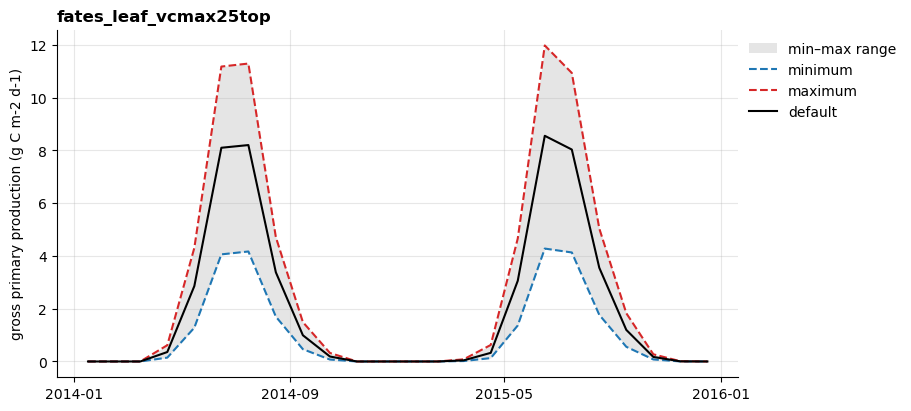

In [106]:
plot_time_series(ensemble, default, 'FATES_GPP', 'fates_leaf_vcmax25top')

## Step 4. Look at sensitivity of annual variables

Next we will calculate annual sums or means of our variables and investigate parameter sensitivity of annual metrics.

Below is a helper function for calculating annual means and sums.

In [204]:
def annual_metric(data_array, type, conversion_factor=None):
    """Calculates annual mean of an input DataArray, applies a 
    conversion factor if supplied
    """
    if conversion_factor is not None:
        data_array = data_array * conversion_factor

    months = data_array["time.daysinmonth"]
    annual_sum = (months * data_array).groupby("time.year").sum()

    if type == 'mean':
        return annual_sum / 365.0
    elif type == 'sum':
        return annual_sum
    raise ValueError(
        f"`type` must be 'mean' or 'sum', not {type}"
    )


variable_dict = {
    'FATES_GPP': 'sum',
    'FCTR': 'mean',
    'FSH': 'mean',
    'FSA': 'mean'
}

Next we will loop through each variable and parameter and calculate parameter sensitivity for as: `abs(hi_value - lo_value)/default`.

In [205]:
dfs = []
sensitivity = {}
for variable in variables:
    for parameter in parameters:

        # calculate annual metric
        ann_var = annual_metric(ensemble[variable], variable_dict[variable])
        ann_default = annual_metric(default[variable], variable_dict[variable])
        
        annual_lo = ann_var.sel(member=get_member(manifest, parameter, "minimum"))
        annual_hi = ann_var.sel(member=get_member(manifest, parameter, "maximum"))
        
        sensitivity[parameter] = (np.abs(annual_hi - annual_lo)/ann_default).mean(dim='year').values
    
    dfs.append(pd.DataFrame(sensitivity, index=[variable]))
sens_df = pd.concat(dfs)

We can then plot a heatmap of these sensitivity values:

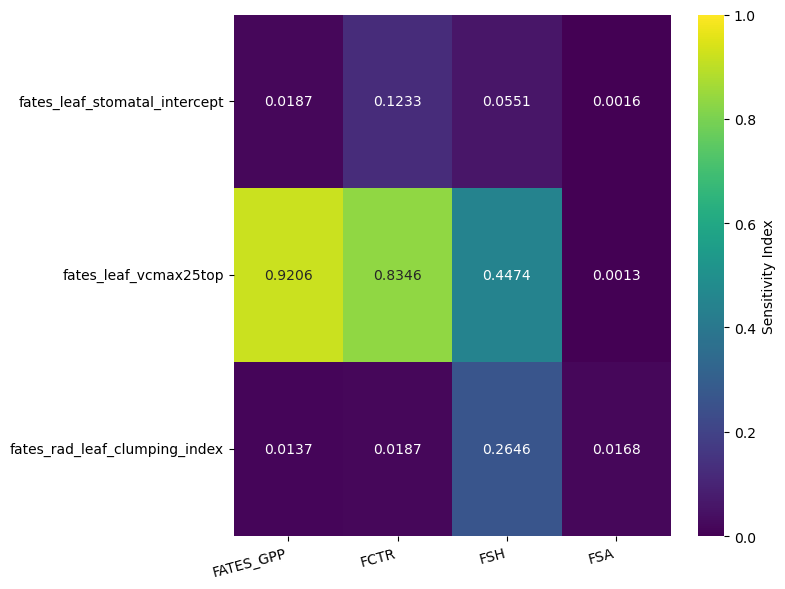

In [210]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    sens_df.T, 
    annot=True, 
    cmap="viridis", 
    fmt=".4f", 
    cbar=True,
    cbar_kws={'label': 'Sensitivity Index'},
    vmin=0,
    vmax=1
)
plt.xticks(rotation=15, ha="right")
plt.yticks(rotation=0)
plt.tight_layout();